In [1]:
import numpy as np
import os

def loadDataSet():
    dataMat = []
    labelMat = []
    file_path = os.path.join(os.path.dirname(os.getcwd()), 'res', 'machinelearninginaction', 'Ch05', 'testSet.txt')
    with open(file_path, 'r', encoding='utf-8') as f:
        lines = f.readlines()
        for line in lines:
            lineArr = line.strip().split()
            dataMat.append([1.0, float(lineArr[0]), float(lineArr[1])]) # 构建 偏置项 和 两个特征项
            labelMat.append(int(lineArr[2])) # 构建标签矩阵
        return dataMat, labelMat

def sigmoid(inX):
    return 1.0/(1+np.exp(-inX))

def gradAscent(dataMatIn, classLabels):
    dataMatrix = np.array(dataMatIn)
    labelMat = np.array(classLabels).reshape(-1, 1) # 转为列向量
    m, n = np.shape(dataMatrix)
    alpha = 0.001
    maxCycles = 500
    weights = np.ones((n, 1))

    for k in range(maxCycles):
        h = sigmoid(dataMatrix @ weights) # h = sigmoid(dataMatrix @ weights) 矩阵乘法
        error = (labelMat - h) # 真实标签 - 预测概率
        weights = weights + alpha * dataMatrix.T @ error # 这两步定义了梯度
    return weights

# Logistic回归
假设有一些数据点，用一条直线对这些点进行拟合叫做回归。利用Logistic回归进行分类的主要思想是：根据现有数据对分类边界线建立回归公式，以此进行分类。  
回归一词源于最佳拟合，表示要找到的最佳拟合参数集。  

## 使用梯度上升找到最佳参数

```markdown
每个回归系数初始化为1
重复R次：
    计算整个数据集的梯度
    使用alpha×gradient更新回归系数的向量
返回回归系数
```


In [2]:
dataArr, labelMat = loadDataSet()
gradAscent(dataArr, labelMat)

array([[ 4.12414349],
       [ 0.48007329],
       [-0.6168482 ]])

## 画出决策边界

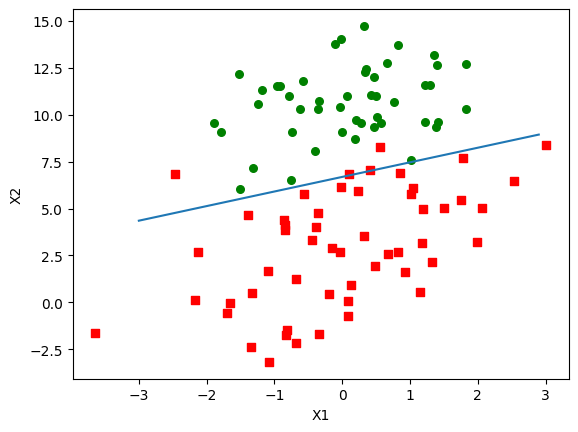

In [3]:
def plotBestFit(weights):
    import matplotlib.pyplot as plt
    dataMat, labelMat = loadDataSet()          # dataMat 是列表的列表，labelMat 是列表
    dataArr = np.array(dataMat)                # 转为 (m, 3) 数组
    n = dataArr.shape[0]
    xcord1, ycord1 = [], []
    xcord2, ycord2 = [], []
    for i in range(n):
        if labelMat[i] == 1:                   # labelMat[i] 已经是 int
            xcord1.append(dataArr[i, 1])
            ycord1.append(dataArr[i, 2])
        else:
            xcord2.append(dataArr[i, 1])
            ycord2.append(dataArr[i, 2])
    fig = plt.figure()
    ax = fig.add_subplot(111)
    ax.scatter(xcord1, ycord1, s=30, c='red', marker='s')
    ax.scatter(xcord2, ycord2, s=30, c='green')
    x = np.arange(-3.0, 3.0, 0.1)
    # weights 形状为 (3,1)，需要压平为 (3,)
    w = weights.flatten()                      # 或者使用 weights.ravel()
    y = (-w[0] - w[1] * x) / w[2]
    ax.plot(x, y)
    plt.xlabel('X1')
    plt.ylabel('X2')
    plt.show()

weights = gradAscent(dataArr, labelMat)   # weights 形状 (3,1)
plotBestFit(weights)  

# 随机梯度上升
梯度上升算法每次更新回归系数时都需要遍历整个数据集

```markdown
所有回归系数初始化为1
对数据集中每个样本
    计算该样本的梯度
    使用alpha×gradient更新回归系数值
返回回归系数值
```

这个版本里面没有真正的随机，而是用单个样本梯度近似整体梯度

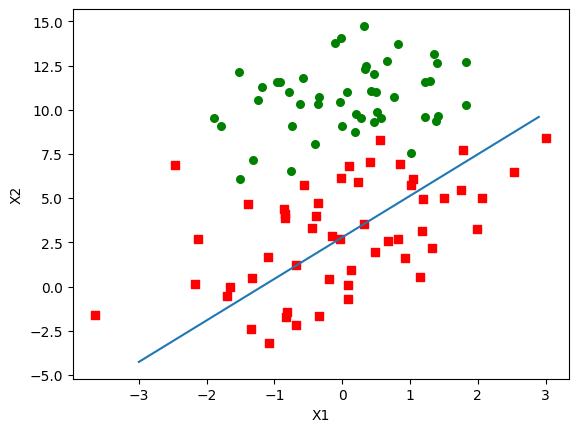

In [7]:
def stocGradAscent0(dataMatrix, classLabels):
    m, n = np.shape(dataMatrix)
    alpha = 0.01
    weights = np.ones(n)
    for i in range(m):
        h = sigmoid(sum(dataMatrix[i] * weights)) # 只计算第i行样本，逐元素相乘 再求和，用sigmoid计算概率
        error = classLabels[i] - h # 单样本误差
        weights = weights + alpha * error * dataMatrix[i] # 逐个样本更新权重
    return weights

dataArr, labelMat = loadDataSet()
weights = stocGradAscent0(np.array(dataArr), labelMat)
plotBestFit(weights)

## 改进的随机梯度上升算法
- `随机选样本，用过即删`
- `动态衰减 alpha = 4/(1+j+i) + 0.0001`

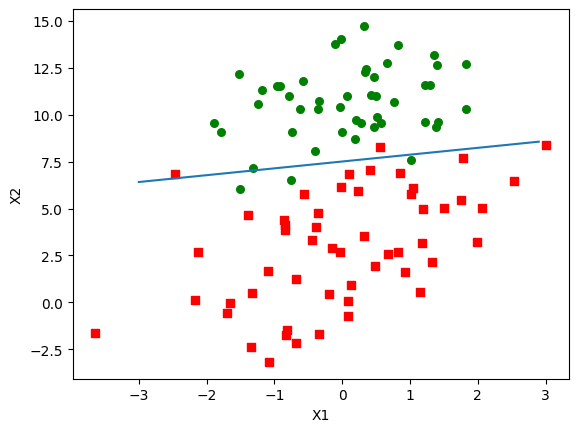

In [ ]:
import random
def stocGradAscent1(dataMatrix, classLabels, numIter=150):
    m, n = np.shape(dataMatrix)
    weights = np.ones(n)
    for j in range(numIter):
        dataIndex = list(range(m))
        for i in range(m): # 每轮抽 m 次，直到池子抽空
            alpha = 4 / (1.0 + j + i) + 0.01
            randIndex = int(random.uniform(0, len(dataIndex))) # 返回一个 [0, len(dataIndex)] 区间内的随机浮点数，并转换成整数
            h = sigmoid(sum(dataMatrix[randIndex] * weights))
            error = classLabels[randIndex] - h
            weights = weights + alpha * error * dataMatrix[randIndex]
            del(dataIndex[randIndex]) # 用过就删，保证不重复
    return weights

dataArr, labelMat = loadDataSet()
weights = stocGradAscent1(np.array(dataArr), labelMat)
plotBestFit(weights)